# 1. Effective Hamiltonian and its exact diagonalization

**Thesis:** Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona (2026). [Read the thesis](https://hdl.handle.net/2445/231684).

**Reading guide:** Sections 3.6–3.7, pp. 20–22; Eqs. (41)–(47); Figure 2. Page numbers below are the printed thesis pages. Equations retain the thesis notation and numbering; an extract from a longer equation is identified as an extract.

**Evidence:** the physics text describes the theoretical model and numerical calculations reported in the thesis. It does not add experimental results or new derivations. Calculation cells come from the original uploaded scripts at commit `22959963191fcbc4d283ec4b272b506ad6dd979b`. Short setup cells only handle notebook execution and display.

Read each explanation, then run its code cell. Source discrepancies and notebook adaptations are labelled explicitly.

**Notebook setup / execution control:** Imports used by the scripts; locate the repository data directory and display plots inline.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
from timeit import default_timer as timer
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'scripts').is_dir() and (p / 'data').is_dir())
DATA = ROOT / 'data'

## 1. Parameters and the two-site Hamiltonian

**Thesis source:** Section 3.6, pp. 20–21, Eqs. (41)–(45). Explanations below paraphrase this passage.

Section 3.6 introduces the two quantities
$$A_X\equiv\frac{\Omega_\alpha^2}{X},\qquad
S_j(X)\equiv\Omega_\beta^2\sum_{\ell=-\infty}^{\infty}
\frac{J_\ell^2(\kappa)}{X+\widetilde\nu_j+\ell\omega'}.\tag{41}$$
$X$ is the interaction-energy difference entering a denominator. The diagonal operator in Eq. (42) uses these quantities. For example, its first term is
$$-2A_{C_{01}-2C_{00}}\,|00\rangle\langle00|\qquad\text{[extract from Eq. (42)].}$$
The off-diagonal operator in Eq. (43) connects $01\leftrightarrow10$, $11\leftrightarrow20$, $02\leftrightarrow11$, and $12\leftrightarrow21$.

**Code reading:** `heff2_couplings` calculates the diagonal entries `Eb` and signed exchange coefficients `gs`. Its finite sideband cutoff is `LMAX`. **Code-specific operation:** with `COMPENSATE_11BLOCK=True`, the script replaces the $11$ diagonal by the $20$ diagonal; this is retained exactly as uploaded. The function does not recompute its detunings after this operation.

**Symbols — Table 1, Section 3.3, and Figure 3.**

| Thesis symbol | Meaning | Script name |
|---|---|---|
| $C_{ij}$ | Interaction-shift parameters | `C00`, `C01`, … |
| $\Omega_\alpha,\Omega_\beta$ | Coupling amplitudes | `Om_a`, `Om_b` |
| $\omega'$ | Modulation frequency | `WP` or `wp` |
| $A$ | Modulation amplitude | `A` |
| $\kappa=A/\omega'$ | Modulation index | `kap` or `kappa` |
| $\widetilde\nu_j$ | Floquet detuning at site $j$ | `nu`, `nt0`, `nt1` |
| $J_\ell(\kappa)$ | Bessel function of order $\ell$ | `jv(ells, ...)` |
| $L$, $N$ | Number of sites; total occupation | `L`, `N` |

**Source convention:** the thesis and original scripts label these numerical energies/rates in MHz and use $\hbar=1$ for evolution. Their original labels and numbers are retained here. **Source discrepancy:** the `heff2_states.py` header equates MHz with rad/µs, whereas thesis Appendix B writes $\omega'/(2\pi)=40$ MHz. This notebook reproduces the supplied convention; it does not resolve that frequency conversion or introduce a replacement time variable.

**Code source:** [`heff2_E_vs_N.py`, lines 47–67](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L47-L67).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [2]:
L = 10
usePBC = False
d = 3

WP = 40.0                 # drive frequency [MHz]
THETA = 0.0               # drive phase; statistical angle phi = -theta
N_RES = 1
CACHE = 'heff2_E_vs_N_L%d.npz' % L

# =====================================================================
# 1.  H_eff^(2) COUPLINGS
# =====================================================================
C00, C01, C11 = 0.0, 20.0, 15.0
C02 = 2.0 * C11
C12, C22 = 45.0, 55.0
Om_a, Om_b = 1.0, 1.0
A = 48.0
COMPENSATE_11BLOCK = True

LMAX = 60
ells = np.arange(-LMAX, LMAX + 1)

**Code source:** [`heff2_E_vs_N.py`, lines 70–104](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L70-L104).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [3]:
def heff2_couplings(wp):
  kap = A / wp
  nu = 2 * C11 - C02 - N_RES * wp
  Jl = jv(ells, kap)

  def ss(dc):
    den = dc + nu + ells * wp
    if np.any(np.abs(den) < 1e-9):
      raise ZeroDivisionError('resonant Stark denominator at wp=%g' % wp)
    return float(np.sum(Jl**2 / den))

  E = {}
  E['00'] = -2 * Om_a**2 / (C01 - 2 * C00)
  E['01'] = (Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01)
             - Om_b**2 * ss(C02 - C01))
  E['02'] = Om_b**2 * ss(C02 - C01) - Om_a**2 / (C12 - C02)
  E['10'] = E['01']
  E['11'] = 2 * Om_a**2 / (2 * C11 - C01) - 2 * Om_b**2 * ss(C12 - 2 * C11)
  E['12'] = (Om_a**2 / (C12 - C02) + Om_b**2 * ss(C12 - 2 * C11)
             - Om_b**2 * ss(2 * C22 - C12))
  E['20'] = E['02']
  E['21'] = E['12']
  E['22'] = 2 * Om_b**2 * ss(2 * C22 - C12)
  if COMPENSATE_11BLOCK:
    E['11'] += E['20'] - E['11']

  g1 = Om_a**2 * (1.0 / (C01 - 2 * C00) - 1.0 / (2 * C11 - C01))
  pref = Om_a * Om_b * (1.0 / (2 * C11 - C01) - 1.0 / (C12 - C02))
  g2 = pref * jv(N_RES, kap)
  g3 = pref * jv(N_RES, kap)
  Sig = (1.0 / (C12 - 2 * C11 + nu + ells * wp)
         - 1.0 / (2 * C22 - C12 + nu + ells * wp))
  g4 = Om_b**2 * float(np.sum(Jl * jv(ells, kap) * Sig))
  Eb = np.array([[E['%d%d' % (a, b)] for b in range(d)] for a in range(d)])
  return Eb, (g1, g2, g3, g4)

**Code source:** [`heff2_E_vs_N.py`, lines 107–109](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L107-L109).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [4]:
def phases_of(theta):
  a, b = 0.0, theta                        # alpha = 0, beta = theta
  return -a, b - 2 * a, a - 2 * b, -b

## 2. Exact diagonalization: from a bond to the chain

**Thesis source:** Section 3.7, pp. 21–22, Eq. (46), Figure 2. Explanations below paraphrase this passage.

The thesis promotes the two-site operator to the chain through
$$H=\sum_j H^{(2)}_{\mathrm{eff},j,j+1}\qquad\text{[Section 3.7, unnumbered].}$$
Figure 2 uses $L=10$ and open boundaries. Each site has the states $|0\rangle$, $|1\rangle$, and $|2\rangle$, so the complete space contains $3^{10}=59049$ configurations.

The conserved occupation operator is
$$\widehat N=\sum_j\widehat n_j,\qquad
\widehat n_j=\sum_{n=0}^{2}n|n\rangle_j\langle n|_j.\tag{46}$$
The diagonal terms preserve occupation and the exchange terms move occupation between neighbours. Section 3.7 states that $\widehat N$ commutes with the effective Hamiltonian. The calculation can therefore be performed separately in each particle-number sector.

**Code reading:** `configs` lists all configurations; `Nvec` gives their total occupation; `BONDS` lists neighbouring sites. `PW` stores the base-three weights used to locate the configurations after a hop.

**Code source:** [`heff2_E_vs_N.py`, lines 115–124](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L115-L124).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [5]:
configs = np.array(list(product(range(d), repeat=L)), dtype=np.int8)
Nvec = configs.sum(axis=1).astype(int)
PW = np.array([d**(L - 1 - j) for j in range(L)], dtype=np.int64)
DIMFULL = d**L
BONDS = [(j, j + 1) for j in range(L - 1)]
if usePBC:
  BONDS.append((L - 1, 0))

TH = phases_of(THETA)
REAL_PATH = all(abs(np.sin(t)) < 1e-14 for t in TH)

## 3. Exact diagonalization: construct each sector matrix

**Thesis source:** Section 3.7, p. 21; construction in Eqs. (42)–(43). Explanations below paraphrase this passage.

Section 3.7 diagonalizes the $2L+1$ particle-number blocks separately. For $L=10$, the largest block contains 8953 states, rather than 59049 states for the complete space.

**Code reading — `sector_levels(N, Eb, gs)`:**

1. `rows` selects the configurations with total occupation `N`; `pos` maps their full-space indices to block indices.
2. `diag` adds the diagonal energy from every bond.
3. The four exchange processes supply the off-diagonal entries. The reverse entries use the complex conjugate.
4. `np.linalg.eigvalsh(H)` returns every eigenvalue of the block. The function also returns its trace.

This is the dense, sector-by-sector spectrum calculation in the uploaded script. Appendix C's matrix-free Lanczos calculation is presented separately in Notebook 05.

**Code source:** [`heff2_E_vs_N.py`, lines 127–156](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L127-L156).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [6]:
def sector_levels(N, Eb, gs):
  """All eigenvalues of H_eff^(2) in the sector of particle number N."""
  rows = np.where(Nvec == N)[0]
  dim = len(rows)
  pos = np.full(DIMFULL, -1, dtype=np.int64)
  pos[rows] = np.arange(dim)
  cfg = configs[rows]
  g1, g2, g3, g4 = gs
  dtype = np.float64 if REAL_PATH else np.complex128
  H = np.zeros((dim, dim), dtype=dtype)
  diag = np.zeros(dim)
  for (jL, jR) in BONDS:
    diag += Eb[cfg[:, jL], cfg[:, jR]]
  H[np.arange(dim), np.arange(dim)] = diag
  for (jL, jR) in BONDS:
    for (a, b), (a2, b2), g, t in [((0, 1), (1, 0), g1, TH[0]),
                                   ((1, 1), (2, 0), g2, TH[1]),
                                   ((0, 2), (1, 1), g3, TH[2]),
                                   ((1, 2), (2, 1), g4, TH[3])]:
      if g == 0.0:
        continue
      amp = g * np.cos(t) if REAL_PATH else g * np.exp(1j * t)
      sel = np.where((cfg[:, jL] == a) & (cfg[:, jR] == b))[0]
      if sel.size == 0:
        continue
      tgt = pos[rows[sel] + (a2 - a) * PW[jL] + (b2 - b) * PW[jR]]
      H[tgt, sel] += amp
      H[sel, tgt] += np.conj(amp)
  tr = float(np.trace(H).real)
  return np.linalg.eigvalsh(H), tr

## 4. Run one sector and load the complete archived spectrum

**Thesis source:** Sections 3.7–3.8.2, pp. 21 and 26. Explanations below paraphrase this passage.

The original calculation combines every block to obtain all $3^{10}=59049$ levels. The saved file contains these energies and their integer particle-number labels.

**Notebook execution choice:** run the original `sector_levels` function for the 55-state $N=2$ block, then load the archived complete spectrum. The full dense calculation remains available below behind `RUN_FULL_ED`; leave it false for an ordinary notebook run. This control changes which job is executed, not the matrix construction.

**Code source:** [`heff2_E_vs_N.py`, lines 162–163](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L162-L163).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [7]:
Eb, gs = heff2_couplings(WP)
g1, g2, g3, g4 = gs

**Notebook setup / execution control:** Call the original sector solver on one small block; these printed values are newly computed.

In [8]:
N_DEMO = 2
demo_energy, demo_trace = sector_levels(N_DEMO, Eb, gs)
print('Live sector N =', N_DEMO, 'dimension =', len(demo_energy))
print('Lowest energies:', demo_energy[:5])

Live sector N = 2 dimension = 55
Lowest energies: [-0.91933449 -0.90813281 -0.90268063 -0.89106602 -0.88572488]


**Notebook setup / execution control:** Default to the archived full spectrum. Enabling RUN_FULL_ED launches all 21 dense blocks and can be expensive; it does not overwrite the archived data.

In [9]:
RUN_FULL_ED = False
CACHE = DATA / ('heff2_E_vs_N_L%d.npz' % L)

**Notebook setup / execution control:** The full-solve branch is the original block loop from heff2_E_vs_N.py (source lines linked in SOURCE_MAP.md). The default branch reads its saved E, NLAB, and TRACE arrays; cache writing is omitted.

**Original block-loop source:** [heff2_E_vs_N.py, lines 182–192](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L182-L192).

In [10]:
if RUN_FULL_ED:
    Es, Ns, TRACE = [], [], 0.0
    t0 = timer()
    for N in range(2 * L + 1):
      e, tr = sector_levels(N, Eb, gs)
      Es.append(e)
      Ns.append(np.full(e.size, N))
      TRACE += tr
      print('   N = %2d  dim %5d   E in [%+.5f, %+.5f]   (%.1f s)'
            % (N, e.size, e[0], e[-1], timer() - t0))
    E = np.concatenate(Es)
    NLAB = np.concatenate(Ns)
else:
    with np.load(CACHE, allow_pickle=False) as z:
        E, NLAB, TRACE = z['E'].copy(), z['NLAB'].copy(), float(z['TRACE'])
        assert int(z['L']) == L and float(z['theta']) == THETA and float(z['wp']) == WP
print('Complete spectrum:', len(E), 'levels')

Complete spectrum: 59049 levels


**Code source:** [`heff2_E_vs_N.py`, lines 196–201](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L196-L201).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [11]:
order = np.argsort(E)
Esort, Nsort = E[order], NLAB[order]
Ns_ = np.arange(2 * L + 1)
E0N = np.array([E[NLAB == N].min() for N in Ns_])
EmaxN = np.array([E[NLAB == N].max() for N in Ns_])
DIMN = np.array([(NLAB == N).sum() for N in Ns_])

## 5. Checks and reported spectrum

**Thesis source:** Section 3.7, pp. 21–22. Explanations below paraphrase this passage.

The thesis reports that the lowest levels belong to several particle-number sectors. Its global gap connects different sectors and is not a fixed-filling excitation.

**Original code checks:** the number of energies must equal $3^L$; their sum is compared with the matrix trace; the sector dimensions are compared between $N$ and $2L-N$. These checks below are taken from the original script. The subsequent table reports the minimum and maximum energy in each sector.

**Code source:** [`heff2_E_vs_N.py`, lines 206–236](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L206-L236).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [12]:
print('-' * 78)
print('CHECKS')
print('   sum of sector dims = %d  (must be 3^%d = %d)   %s'
      % (E.size, L, DIMFULL, 'PASS' if E.size == DIMFULL else 'FAIL'))
print('   every level has an integer N by construction (H is block diagonal)')
print('   trace sum rule sum_m E_m = Tr H:  |d| = %.2e   %s'
      % (abs(E.sum() - TRACE), 'PASS' if abs(E.sum() - TRACE) < 1e-6 else 'FAIL'))
print('   particle-hole check dim(N) == dim(2L-N):        %s'
      % ('PASS' if np.array_equal(DIMN, DIMN[::-1]) else 'FAIL'))

# =====================================================================
# 5.  RESULTS
# =====================================================================
igs = int(np.argmin(E))
print('-' * 78)
print('RESULTS')
print('   global ground state E_0 = %+.8f MHz  in sector N = %d  (n-bar = %.3f)'
      % (E[igs], NLAB[igs], NLAB[igs] / L))
print('   global maximum      E   = %+.8f MHz  in sector N = %d'
      % (E.max(), NLAB[int(np.argmax(E))]))
print('   bandwidth = %.8f MHz' % (E.max() - E.min()))
print('   per-sector summary:')
print('      %3s %6s %12s %12s %12s' % ('N', 'dim', 'E_0(N)', 'E_max(N)', 'width'))
for N in Ns_:
  print('      %3d %6d %+12.6f %+12.6f %12.6f'
        % (N, DIMN[N], E0N[N], EmaxN[N], EmaxN[N] - E0N[N]))
print('   E_0(N) is minimized at N = %d;  E_0 is NOT monotonic in N'
      % int(np.argmin(E0N)))
print('   the density operator n-bar = N/L has eigenvalues %.3f .. %.3f in '
      'steps of 1/L = %.3f' % (0.0, 2.0, 1.0 / L))
print('=' * 78)

------------------------------------------------------------------------------
CHECKS
   sum of sector dims = 59049  (must be 3^10 = 59049)   PASS
   every level has an integer N by construction (H is block diagonal)
   trace sum rule sum_m E_m = Tr H:  |d| = 1.82e-12   PASS
   particle-hole check dim(N) == dim(2L-N):        PASS
------------------------------------------------------------------------------
RESULTS
   global ground state E_0 = -0.91933449 MHz  in sector N = 2  (n-bar = 0.200)
   global maximum      E   = +0.51653430 MHz  in sector N = 15
   bandwidth = 1.43586880 MHz
   per-sector summary:
        N    dim       E_0(N)     E_max(N)        width
        0      1    -0.900000    -0.900000     0.000000
        1     10    -0.911976    -0.717927     0.194049
        2     55    -0.919334    -0.551307     0.368028
        3    210    -0.919208    -0.411553     0.507654
        4    615    -0.910374    -0.309062     0.601312
        5   1452    -0.892329    -0.248846     0.6

## 6. Plot the spectrum

**Thesis source:** Section 3.7, pp. 21–22, Eq. (47), Figure 2. Explanations below paraphrase this passage.

Figure 2 compares $E$ against $N$ with $E/L$ against the average number density,
$$\bar n=\widehat N/L.\tag{47}$$
The eigenvalues on the horizontal axis are $N/L$. The uploaded spectrum script also includes density-of-states and sector-width panels; those additional source-code panels are retained below and are not labelled as extra thesis figures.

**Code source:** [`heff2_E_vs_N.py`, lines 241–323](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_E_vs_N.py#L241-L323).

**Notebook changes:** Original four-panel source plot; inline display replaces the Agg backend and file export.

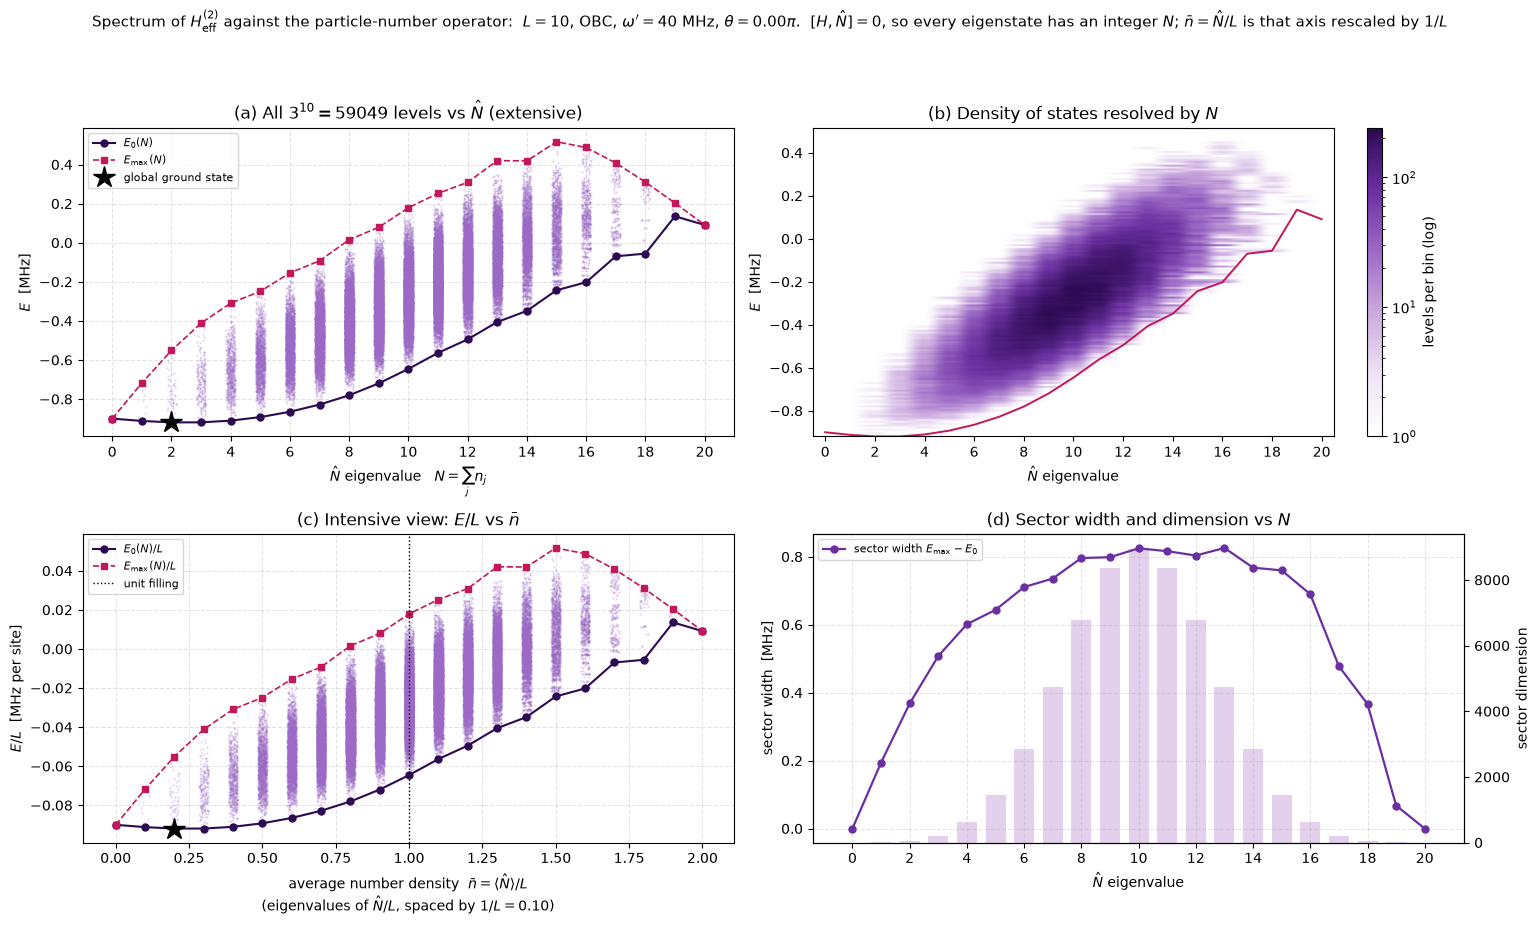

In [13]:
import matplotlib
# Inline backend selected in notebook setup.
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

CMAP = LinearSegmentedColormap.from_list(
    'white_violet', ['#ffffff', '#efe3f5', '#cbaade', '#9c6ac6', '#6a2fa0',
                     '#2c0a52'])

fig, axs = plt.subplots(2, 2, figsize=(15.5, 9.4))
rng = np.random.default_rng(0)

# (a) E vs N-hat eigenvalue
ax = axs[0, 0]
ax.plot(NLAB + 0.30 * (rng.random(NLAB.size) - 0.5), E, '.', ms=1.0,
        color='#9c6ac6', alpha=0.30, rasterized=True)
ax.plot(Ns_, E0N, 'o-', color='#2c0a52', ms=5, lw=1.5, label=r'$E_0(N)$')
ax.plot(Ns_, EmaxN, 's--', color='#c2185b', ms=4, lw=1.2, label=r'$E_{\max}(N)$')
ax.plot([NLAB[igs]], [E[igs]], 'k*', ms=16, label='global ground state')
ax.set_xlabel(r'$\hat N$ eigenvalue   $N=\sum_j n_j$')
ax.set_ylabel(r'$E$  [MHz]')
ax.set_title(r'(a) All $3^{%d}=%d$ levels vs $\hat N$ (extensive)'
             % (L, DIMFULL))
ax.set_xticks(Ns_[::2])
ax.legend(fontsize=8)
ax.grid(True, ls='--', alpha=0.35)

# (b) density of states in the (N, E) plane
ax = axs[0, 1]
nb = 160
H2, xe, ye = np.histogram2d(NLAB, E, bins=[np.arange(2 * L + 2) - 0.5,
                                           np.linspace(E.min(), E.max(), nb)])
im = ax.imshow(H2.T, origin='lower', aspect='auto', cmap=CMAP,
               norm=LogNorm(vmin=1, vmax=max(H2.max(), 2)),
               extent=[-0.5, 2 * L + 0.5, E.min(), E.max()])
fig.colorbar(im, ax=ax, label='levels per bin (log)')
ax.plot(Ns_, E0N, '-', color='#c2185b', lw=1.4)
ax.set_xlabel(r'$\hat N$ eigenvalue')
ax.set_ylabel(r'$E$  [MHz]')
ax.set_title('(b) Density of states resolved by $N$')
ax.set_xticks(Ns_[::2])

# (c) intensive view: E/L vs n-bar = N/L
ax = axs[1, 0]
ax.plot(NLAB / L + (0.30 / L) * (rng.random(NLAB.size) - 0.5), E / L, '.',
        ms=1.0, color='#9c6ac6', alpha=0.30, rasterized=True)
ax.plot(Ns_ / L, E0N / L, 'o-', color='#2c0a52', ms=5, lw=1.5,
        label=r'$E_0(N)/L$')
ax.plot(Ns_ / L, EmaxN / L, 's--', color='#c2185b', ms=4, lw=1.2,
        label=r'$E_{\max}(N)/L$')
ax.plot([NLAB[igs] / L], [E[igs] / L], 'k*', ms=16)
ax.axvline(1.0, color='k', ls=':', lw=1, label='unit filling')
ax.set_xlabel(r'average number density  $\bar n=\langle\hat N\rangle/L$'
              '\n' r'(eigenvalues of $\hat N/L$, spaced by $1/L=%.2f$)' % (1 / L))
ax.set_ylabel(r'$E/L$  [MHz per site]')
ax.set_title(r'(c) Intensive view: $E/L$ vs $\bar n$')
ax.legend(fontsize=8)
ax.grid(True, ls='--', alpha=0.35)

# (d) per-sector envelope and dimension
ax = axs[1, 1]
ax.plot(Ns_, EmaxN - E0N, 'o-', color='#6a2fa0', lw=1.6, ms=5,
        label='sector width $E_{\\max}-E_0$')
ax.set_xlabel(r'$\hat N$ eigenvalue')
ax.set_ylabel('sector width  [MHz]')
ax.set_xticks(Ns_[::2])
ax.grid(True, ls='--', alpha=0.35)
ax2 = ax.twinx()
ax2.bar(Ns_, DIMN, color='#cbaade', alpha=0.55, width=0.7)
ax2.set_ylabel('sector dimension')
ax.set_title('(d) Sector width and dimension vs $N$')
ax.legend(fontsize=8, loc='upper left')
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

fig.suptitle(r'Spectrum of $H_{\mathrm{eff}}^{(2)}$ against the particle-number '
             r'operator:  $L=%d$, %s, $\omega^{\prime}=%g$ MHz, '
             r'$\theta=%.2f\pi$.  $[H,\hat N]=0$, so every eigenstate has an '
             r'integer $N$; $\bar n=\hat N/L$ is that axis rescaled by $1/L$'
             % (L, 'PBC' if usePBC else 'OBC', WP, THETA / np.pi), fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## Source and reproduction record

The original scripts and saved data are unchanged. See [SOURCE_MAP.md](SOURCE_MAP.md) for the thesis-to-code map and [VALIDATION.md](VALIDATION.md) for the checks performed on this revision.